# BÀI TẬP NÂNG CAO với mô hình SARIMA – Dataset 2 (AirPassengers)

## Bước 5. Fit SARIMA(0,1,1)(0,1,1)₁₂

Tập train: 120 tháng đầu. Tập test: 24 tháng cuối.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")

URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
S = 12           # chu kỳ mùa vụ
TEST_SIZE = 24   # 2 năm cuối làm tập kiểm tra

df = pd.read_csv(URL)
df.columns = ["Month", "Passengers"]
df["Month"] = pd.to_datetime(df["Month"])
y = df.set_index("Month")["Passengers"].asfreq("MS")
train, test = y.iloc[:-TEST_SIZE], y.iloc[-TEST_SIZE:]
print(y.shape)
y.head()

(144,)


Month
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: Passengers, dtype: int64

In [2]:
sarima = SARIMAX(train,
                 order=(0, 1, 1),
                 seasonal_order=(0, 1, 1, S),
                 enforce_stationarity=False,
                 enforce_invertibility=False).fit(disp=False)

In [3]:
print(sarima.summary())

                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  120
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                -350.754
Date:                            Tue, 17 Nov 2026   AIC                            707.509
Time:                                    13:22:45   BIC                            715.106
Sample:                                01-01-1949   HQIC                           710.576
                                     - 12-01-1958                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.2380      0.092     -2.599      0.009      -0.418      -0.059
ma.S.L12      -0.0464      0.094   

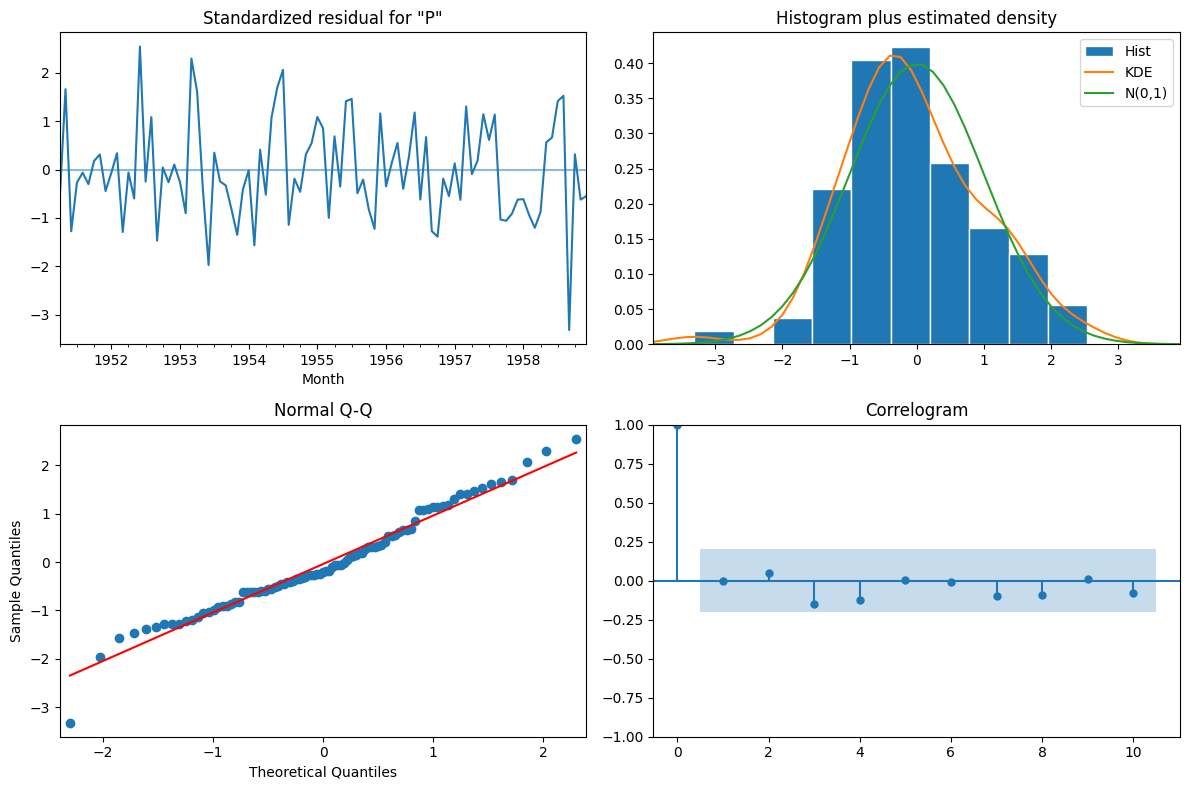

In [4]:
sarima.plot_diagnostics(figsize=(12, 8))
plt.tight_layout(); plt.show()

**Nhận xét:** kiểm tra phần dư (residuals) có giống nhiễu trắng không: không còn tự tương quan, phân phối gần chuẩn.